# Clustering practice

[Contents]

(1) K-mean Clustering  
(2) Hierarchical Clustering(Agglomerative)  
(3) DBSCAN  
(4) 데이터셋에 따른 성과비교 + 시각화(Dendrogram)
  
    
[Data]  
Synthetic datasets by scikit-learn   
https://scikit-learn.org/stable/datasets/sample_generators.html  


[Task]
주어진 판매 데이터를 활용하여 Segmentation(고객 세분화) 진행해보기
 - 적절한 method를 선택하여 Clustering
 - Cluster별 분석을 통해 Profiling 분석(고객특징 분석)  

[Data]  
Wholesale customers Data set  
https://archive.ics.uci.edu/dataset/292/wholesale+customers

[Note]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")


### Comparison of Clustering Methods

1. 합성 데이터 생성

In [ ]:
# 데이터 생성
print("=== 데이터셋 생성 ===")
np.random.seed(42)

# 1.구형 클러스터 데이터(Blob)
X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

# 2.초승달 모양 데이터(Moon)
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

# 데이터 표준화
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(X_blobs)
X_moons_scaled = scaler.fit_transform(X_moons)


=== 데이터셋 생성 ===


2. 클러스터링 평가 함수

In [ ]:

# Dunn Index 함수
def dunn_index(X, labels):
    """Dunn Index function"""
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0

    distances = pdist(X)
    distance_matrix = squareform(distances)

    # 클러스터 간 최소 거리
    min_inter_cluster = float('inf')
    for i in range(len(unique_labels)):
        for j in range(i+1, len(unique_labels)):
            cluster_i = X[labels == unique_labels[i]]
            cluster_j = X[labels == unique_labels[j]]

            min_dist = float('inf')
            for point_i in cluster_i:
                for point_j in cluster_j:
                    dist = np.linalg.norm(point_i - point_j)
                    min_dist = min(min_dist, dist)
            min_inter_cluster = min(min_inter_cluster, min_dist)

    # 클러스터 내 최대 거리
    max_intra_cluster = 0
    for label in unique_labels:
        cluster_points = X[labels == label]
        if len(cluster_points) > 1:
            cluster_distances = pdist(cluster_points)
            max_intra_cluster = max(max_intra_cluster, np.max(cluster_distances))

    return min_inter_cluster / max_intra_cluster if max_intra_cluster > 0 else 0

# 평가 함수
def evaluate_clustering(X, labels, method_name):
    """클러스터링 결과 평가"""
    # 노이즈 포인트 제외 (DBSCAN의 경우 -1 라벨)
    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    if len(np.unique(labels_clean)) <= 1:
        print(f"{method_name} - 클러스터가 1개 이하로 평가 불가")
        return None, None, None

    dunn = dunn_index(X_clean, labels_clean)
    calinski = calinski_harabasz_score(X_clean, labels_clean)
    silhouette = silhouette_score(X_clean, labels_clean)

    print(f"{method_name} 클러스터링 평가:")
    print(f"  Dunn Index: {dunn:.3f} ")
    print(f"  Calinski-Harabasz Index: {calinski:.3f} ")
    print(f"  Silhouette Score: {silhouette:.3f} ")
    print()

    return dunn, calinski, silhouette


3. 클러스터수 결정을 위한 Elbow Method

In [ ]:
# Elbow Method 함수
def elbow_method(X, max_k=10, title="Elbow Method"):
    inertias = []
    K_range = range(1, max_k+1)

    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(8, 4))
    plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Clusters (k)', fontsize=12)
    plt.ylabel('Inertia', fontsize=12)
    plt.title(f'{title}', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.xticks(K_range)
    plt.tight_layout()
    plt.show()

    return inertias

4. 클러스터링 시각화(덴드로그램 포함)

In [ ]:

# 덴드로그램 함수
def plot_dendrogram(X, title):
    plt.figure(figsize=(8, 4))
    linkage_matrix = linkage(X, method='ward')
    dendrogram(linkage_matrix, truncate_mode='level', p=4,
               leaf_rotation=90, leaf_font_size=10)
    plt.title(f'Dendrogram - {title}', fontsize=14, fontweight='bold')
    plt.xlabel('Sample Index', fontsize=12)
    plt.ylabel('Distance', fontsize=12)
    plt.tight_layout()
    plt.show()

# 클러스터링 결과 시각화 함수
def plot_clustering_results(X, algorithms_results, original_labels, data_name):
    """클러스터링 결과를 시각화"""
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle(f'Clustering Results - {data_name}', fontsize=16, fontweight='bold')

    # Original data
    axes[0].scatter(X[:, 0], X[:, 1], c='gray', cmap='viridis', s=30, alpha=0.7)
    axes[0].set_title('Original Data', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Feature 1', fontsize=9)
    axes[0].set_ylabel('Feature 2', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Clustering results
    titles = ['K-Means', 'Hierarchical', 'DBSCAN']

    for i, (title, labels) in enumerate(algorithms_results):
        ax = axes[i + 1]
        scatter = ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30, alpha=0.7)
        ax.set_title(f'{title}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Feature 1', fontsize=9)
        ax.set_ylabel('Feature 2', fontsize=9)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# 클러스터별 통계 출력 함수
def print_cluster_stats(algorithms_results, data_name):
    """클러스터 개수 및 노이즈 포인트 통계 출력"""
    print(f"=== {data_name} 클러스터 정보 ===")
    for name, labels in algorithms_results:
        unique_labels = np.unique(labels)
        n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        n_noise = np.sum(labels == -1) if -1 in unique_labels else 0
        print(f"{name}: {n_clusters}개 클러스터, {n_noise}개 Noise")
    print()

5. Experiment 1 - BLOB Data: Comparison of Clustering Methods

Elbow Method (Blob)
- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점


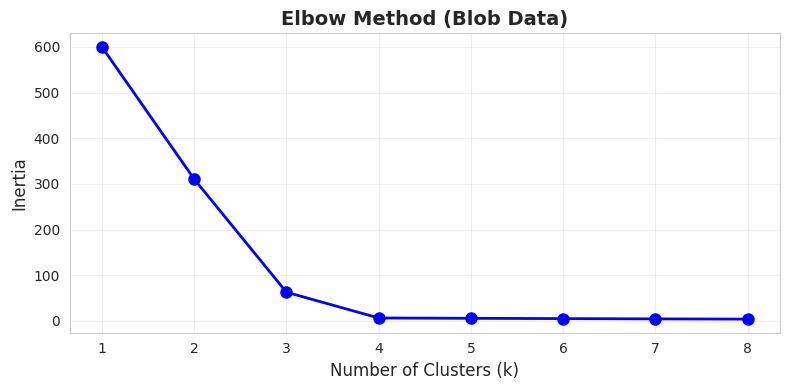

Dendrogram (Blob)


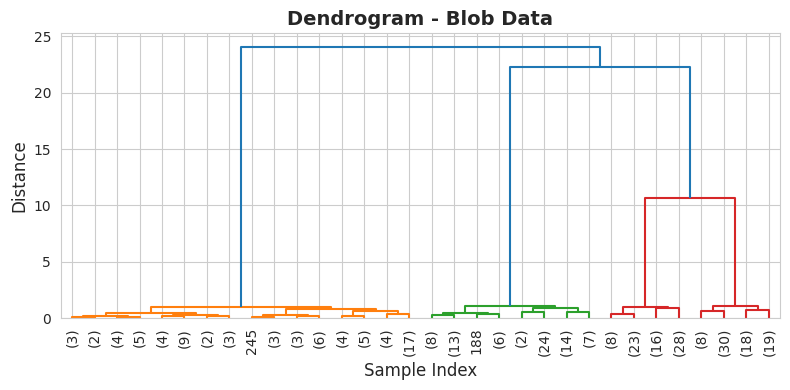

In [ ]:
# Elbow Method
print("Elbow Method (Blob)")
print("- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점")
elbow_method(X_blobs_scaled, max_k=8, title="Elbow Method (Blob Data)")

# Dendrogram
print("Dendrogram (Blob)")
plot_dendrogram(X_blobs_scaled, "Blob Data")

클러스터링 실행 (Blob)


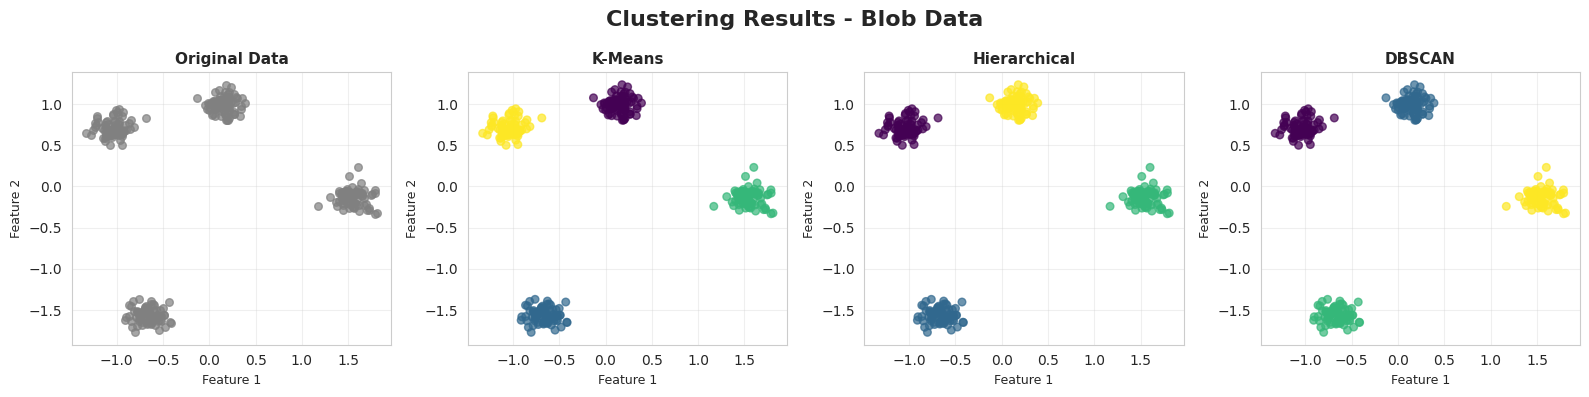

=== Blob Data 클러스터 정보 ===
K-Means: 4개 클러스터, 0개 Noise
Hierarchical: 4개 클러스터, 0개 Noise
DBSCAN: 4개 클러스터, 0개 Noise

성능 평가 (Blob)
K-Means (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

Hierarchical (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

DBSCAN (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 



(np.float64(0.9159222359410192),
 np.float64(9129.065187886943),
 np.float64(0.879591338894901))

In [ ]:
print("클러스터링 실행 (Blob)")

# K-Means
kmeans_blobs = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels_blobs = kmeans_blobs.fit_predict(X_blobs_scaled)

# Hierarchical
hierarchical_blobs = AgglomerativeClustering(n_clusters=4, linkage='ward')
hierarchical_labels_blobs = hierarchical_blobs.fit_predict(X_blobs_scaled)

# DBSCAN
dbscan_blobs = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels_blobs = dbscan_blobs.fit_predict(X_blobs_scaled)

# 결과 시각화
blob_results = [
    ('K-Means', kmeans_labels_blobs),
    ('Hierarchical', hierarchical_labels_blobs),
    ('DBSCAN', dbscan_labels_blobs)
]

plot_clustering_results(X_blobs_scaled, blob_results, y_blobs, "Blob Data")

# 클러스터 정보
print_cluster_stats(blob_results, "Blob Data")

# 성능 평가
print("성능 평가 (Blob)")
evaluate_clustering(X_blobs_scaled, kmeans_labels_blobs, "K-Means (Blob)")
evaluate_clustering(X_blobs_scaled, hierarchical_labels_blobs, "Hierarchical (Blob)")
evaluate_clustering(X_blobs_scaled, dbscan_labels_blobs, "DBSCAN (Blob)")


6. Experiment 2 - Moon Data: Comparison of Clustering Methods

Elbow Method (Moon)


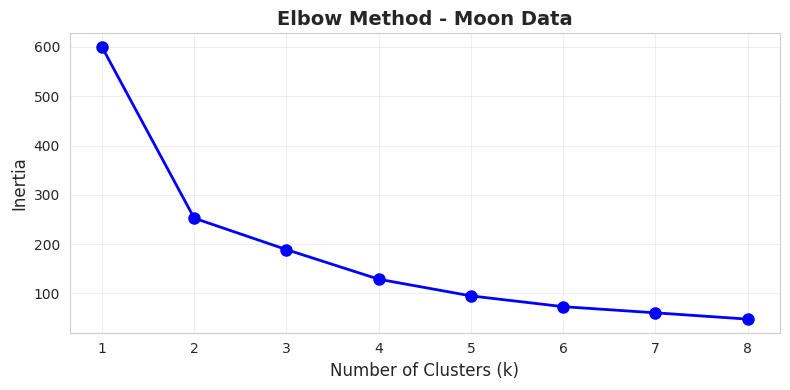

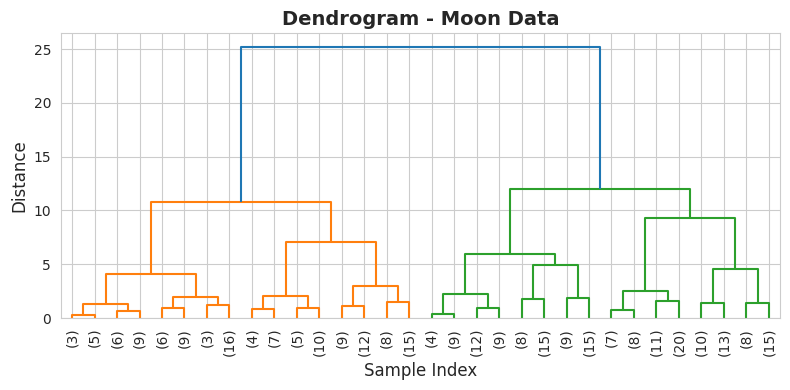

In [ ]:
# Elbow Method
print("Elbow Method (Moon)")
elbow_method(X_moons_scaled, max_k=8, title="Elbow Method - Moon Data")

# Dendrogram
plot_dendrogram(X_moons_scaled, "Moon Data")


클러스터링 실행 (Moon)


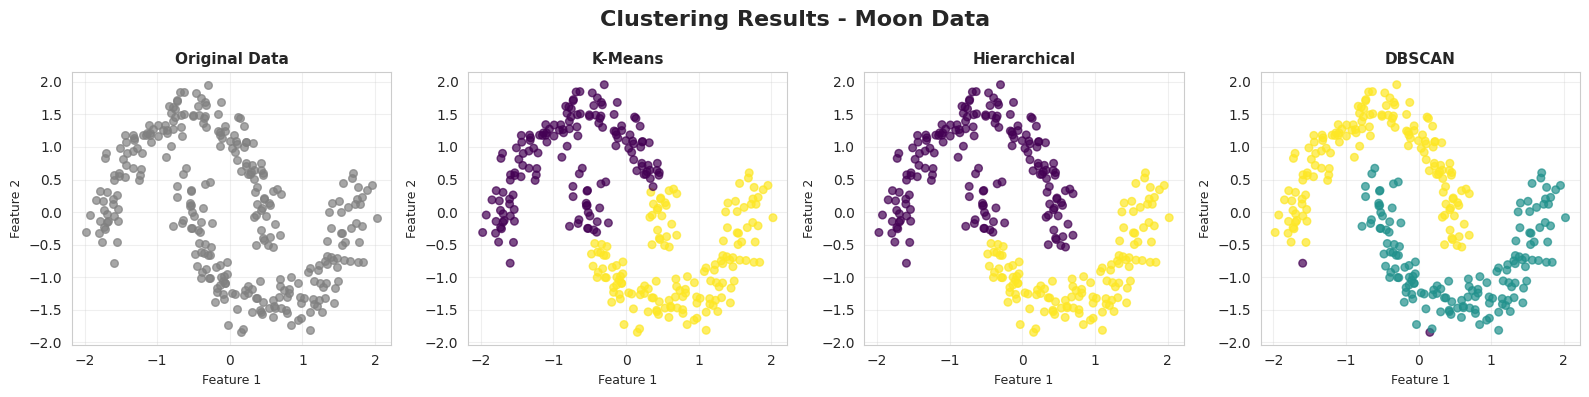

=== Moon Data 클러스터 정보 ===
K-Means: 2개 클러스터, 0개 Noise
Hierarchical: 2개 클러스터, 0개 Noise
DBSCAN: 2개 클러스터, 2개 Noise

K-Means (Moon) 클러스터링 평가:
  Dunn Index: 0.030 
  Calinski-Harabasz Index: 409.607 
  Silhouette Score: 0.491 

Hierarchical (Moon) 클러스터링 평가:
  Dunn Index: 0.058 
  Calinski-Harabasz Index: 335.133 
  Silhouette Score: 0.448 

DBSCAN (Moon) 클러스터링 평가:
  Dunn Index: 0.109 
  Calinski-Harabasz Index: 251.643 
  Silhouette Score: 0.376 



(np.float64(0.10859013652887294),
 np.float64(251.6427781189682),
 np.float64(0.3763520621462321))

In [ ]:
print("클러스터링 실행 (Moon)")

# K-Means
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels_moons = kmeans_moons.fit_predict(X_moons_scaled)

# Hierarchical
hierarchical_moons = AgglomerativeClustering(n_clusters=2, linkage='ward')
hierarchical_labels_moons = hierarchical_moons.fit_predict(X_moons_scaled)

# DBSCAN
dbscan_moons = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels_moons = dbscan_moons.fit_predict(X_moons_scaled)

# 결과 시각화
moon_results = [
    ('K-Means', kmeans_labels_moons),
    ('Hierarchical', hierarchical_labels_moons),
    ('DBSCAN', dbscan_labels_moons)
]

plot_clustering_results(X_moons_scaled, moon_results, y_moons, "Moon Data")

# 클러스터 정보
print_cluster_stats(moon_results, "Moon Data")

# 성능 평가
evaluate_clustering(X_moons_scaled, kmeans_labels_moons, "K-Means (Moon)")
evaluate_clustering(X_moons_scaled, hierarchical_labels_moons, "Hierarchical (Moon)")
evaluate_clustering(X_moons_scaled, dbscan_labels_moons, "DBSCAN (Moon)")

### Task: Segmentation(고객 세분화)  

- 8개 변수를 활용하여 클러스터링+프로파일링 진행하기


In [ ]:
!pip install ucimlrepo

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo
import pandas as pd

# UCI에서 데이터 불러오기
wholesale_customers = fetch_ucirepo(id=292)

X = wholesale_customers.data.features
y = wholesale_customers.data.targets

# Concatenate후 살펴보기
df = pd.concat([X, y], axis=1)

print(f"Data Shape: {df.shape}")
print(f"Categorical Variable: {X.select_dtypes(include=['object']).columns.tolist()}")
print(f"Info: {df.info()}")

print(f"{df.head(5)}")


Data Shape: (440, 8)
Categorical Variable: []
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Fresh             440 non-null    int64
 2   Milk              440 non-null    int64
 3   Grocery           440 non-null    int64
 4   Frozen            440 non-null    int64
 5   Detergents_Paper  440 non-null    int64
 6   Delicassen        440 non-null    int64
 7   Region            440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
Info: None
   Channel  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Region
0        2  12669  9656     7561     214              2674        1338       3
1        2   7057  9810     9568    1762              3293        1776       3
2        2   6353  8808     7684    2405              3516        7844       3
3        1  13265  1196     4221    6404     

---

## Step 0. 이번 실습의 원칙

지도학습(실습1·2)과 달리 **정답이 없다.** 그래서 "몇 점이냐"가 아니라
**"이 묶음이 말이 되느냐"** 로 판단해야 한다.

| 원칙 | 이유 |
| --- | --- |
| `Channel`·`Region` 은 **입력에서 제외** | 이미 아는 답을 다시 발견하는 셈. **검증용으로 남긴다** |
| 지출 6개 변수만 사용 | 실제 구매 행동만으로 묶어야 새 정보가 된다 |
| 지표는 **클러스터 크기와 함께** 본다 | 실루엣은 이상치를 떼어내도 올라간다 |
| **Profiling 이 최종 산출물** | 실루엣 점수는 중간 과정일 뿐 |

In [2]:
# ============================================================
# Step 0. 공통 설정
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, cdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             adjusted_rand_score)

RS = 42
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
VALID = [c for c in ["Channel", "Region"] if c in df.columns]   # 검증용(입력 아님)

Xs = df[SPEND].copy()
print(f"전체 {df.shape[0]}명 x {df.shape[1]}개 컬럼")
print(f"  클러스터링 입력 : {SPEND}")
print(f"  검증용(제외)    : {VALID}")
for v in VALID:
    print(f"    {v} 분포 = {df[v].value_counts().sort_index().to_dict()}")

def dunn_fast(X, labels):
    """교재 p.69 Dunn Index (벡터화 버전). 클수록 좋음."""
    ls = np.unique(labels)
    if len(ls) < 2: return 0.0
    groups = [X[labels == l] for l in ls]
    inter = min(cdist(a, b).min() for i, a in enumerate(groups) for b in groups[i+1:])
    intra = max(pdist(g).max() if len(g) > 1 else 0 for g in groups)
    return inter / intra if intra > 0 else 0.0

def score_all(X, labels):
    """노이즈(-1)는 제외하고 세 지표를 한 번에."""
    m = labels != -1
    Xc, lc = X[m], labels[m]
    if len(np.unique(lc)) < 2: return dict(silhouette=np.nan, ch=np.nan, dunn=np.nan)
    return dict(silhouette=silhouette_score(Xc, lc),
                ch=calinski_harabasz_score(Xc, lc),
                dunn=dunn_fast(Xc, lc))

def sizes(labels):
    u, c = np.unique(labels[labels != -1], return_counts=True)
    return c.tolist()

전체 440명 x 8개 컬럼
  클러스터링 입력 : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
  검증용(제외)    : ['Channel', 'Region']
    Channel 분포 = {1: 298, 2: 142}
    Region 분포 = {1: 77, 2: 47, 3: 316}


---

## Step 2. 데이터 실사 — 이 데이터의 두 가지 문제

교재 p.44: *"객체를 벡터로 표현 → 벡터간 거리 산출 → 거리 기반 군집화"*
즉 **거리가 전부**다. 그런데 이 데이터는 거리를 그대로 재면 안 되는 이유가 두 개 있다.

In [3]:
# ============================================================
# Step 2-1. 문제 ① 분포가 극단적으로 치우쳐 있다
# ============================================================
desc = pd.DataFrame({
    "중앙값": Xs.median().round(0),
    "평균":   Xs.mean().round(0),
    "최대":   Xs.max(),
    "최대/중앙값": (Xs.max() / Xs.median()).round(1),
    "왜도(skew)": Xs.skew().round(2),
})
print("=== 지출 6개 변수의 분포 ===")
print(desc.to_string())
print("\n[해석] 왜도 11 은 '대부분 작은 값인데 몇 명이 어마어마하게 크다' 는 뜻이다.")
print("       최대/중앙값이 50배 -> 이대로 거리를 재면 이상치 몇 명이 전체를 지배한다.")
print("       (실습2 에서 area 가 거리의 99% 를 차지했던 것과 같은 문제)")

# 원척도에서 각 변수가 거리에 기여하는 비중
raw_share = (Xs.var() / Xs.var().sum()).sort_values(ascending=False)
log_share = (np.log1p(Xs).var() / np.log1p(Xs).var().sum()).sort_values(ascending=False)
print("\n=== 표준화 '전' 거리 기여도 (분산 비중) ===")
print(f"{'변수':>18} | {'원척도':>8} | {'로그변환':>8}")
for c in SPEND:
    print(f"{c:>18} | {raw_share[c]*100:7.1f}% | {log_share[c]*100:7.1f}%")
print(f"\n  원척도 최대 변수가 {raw_share.max()*100:.0f}% 를 차지 -> 로그 후 {log_share.max()*100:.0f}% 로 완화")

=== 지출 6개 변수의 분포 ===
                     중앙값       평균      최대  최대/중앙값  왜도(skew)
Fresh             8504.0  12000.0  112151    13.2      2.56
Milk              3627.0   5796.0   73498    20.3      4.05
Grocery           4756.0   7951.0   92780    19.5      3.59
Frozen            1526.0   3072.0   60869    39.9      5.91
Detergents_Paper   816.0   2881.0   40827    50.0      3.63
Delicassen         966.0   1525.0   47943    49.7     11.15

[해석] 왜도 11 은 '대부분 작은 값인데 몇 명이 어마어마하게 크다' 는 뜻이다.
       최대/중앙값이 50배 -> 이대로 거리를 재면 이상치 몇 명이 전체를 지배한다.
       (실습2 에서 area 가 거리의 99% 를 차지했던 것과 같은 문제)

=== 표준화 '전' 거리 기여도 (분산 비중) ===
                변수 |      원척도 |     로그변환
             Fresh |    44.6% |    20.0%
              Milk |    15.2% |    10.8%
           Grocery |    25.2% |    11.4%
            Frozen |     6.6% |    15.2%
  Detergents_Paper |     6.3% |    27.0%
        Delicassen |     2.2% |    15.5%

  원척도 최대 변수가 45% 를 차지 -> 로그 후 27% 로 완화


=== 상관계수 ===
                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Fresh              1.00  0.10    -0.01    0.35             -0.10        0.24
Milk               0.10  1.00     0.73    0.12              0.66        0.41
Grocery           -0.01  0.73     1.00   -0.04              0.92        0.21
Frozen             0.35  0.12    -0.04    1.00             -0.13        0.39
Detergents_Paper  -0.10  0.66     0.92   -0.13              1.00        0.07
Delicassen         0.24  0.41     0.21    0.39              0.07        1.00

상관이 높은 조합 Top3
  Grocery <-> Detergents_Paper : r = 0.92
  Milk <-> Grocery : r = 0.73
  Milk <-> Detergents_Paper : r = 0.66

[해석] Grocery/Detergents_Paper/Milk 는 사실상 '소매점이 함께 사는 물건' 묶음이다.
       6개 변수처럼 보이지만 독립적인 정보는 그보다 적다. (실습2 와 같은 구조)


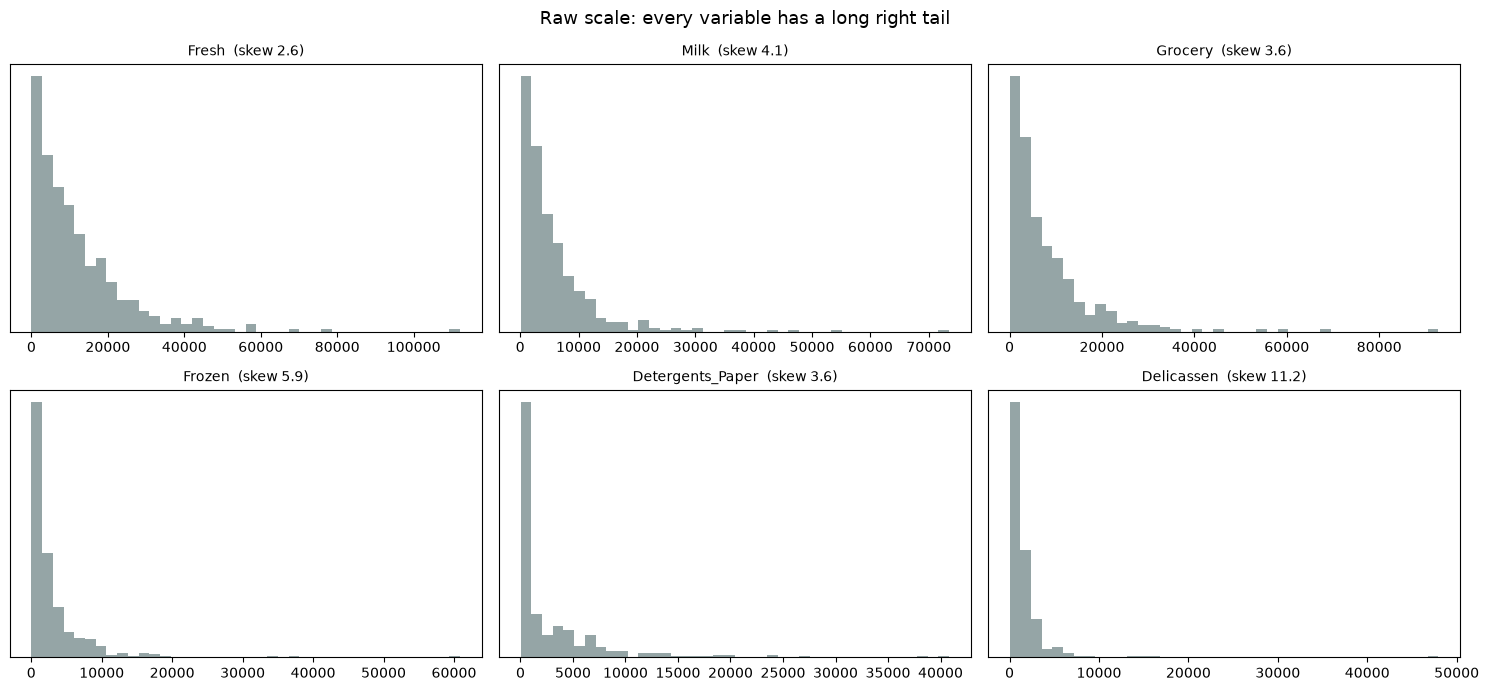

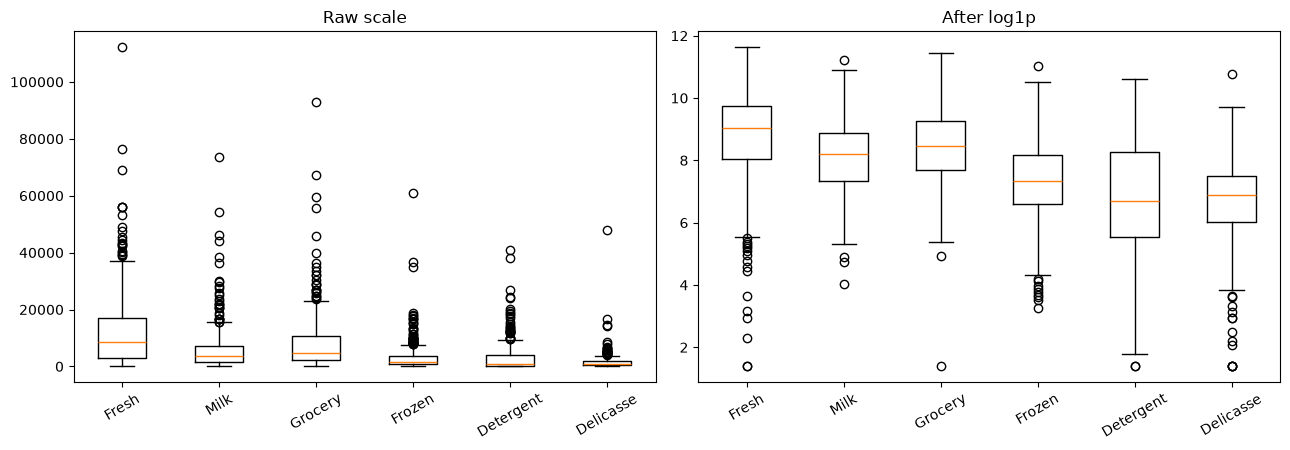

In [4]:
# ============================================================
# Step 2-2. 문제 ② 변수끼리 중복이 심하다
# ============================================================
corr = Xs.corr()
print("=== 상관계수 ===")
print(corr.round(2).to_string())
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(SPEND) for b in SPEND[i+1:]]
pairs.sort(key=lambda t: -abs(t[2]))
print("\n상관이 높은 조합 Top3")
for a, b, v in pairs[:3]:
    print(f"  {a} <-> {b} : r = {v:.2f}")
print("\n[해석] Grocery/Detergents_Paper/Milk 는 사실상 '소매점이 함께 사는 물건' 묶음이다.")
print("       6개 변수처럼 보이지만 독립적인 정보는 그보다 적다. (실습2 와 같은 구조)")

# --- [그림 1] 분포와 상관 ---
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(SPEND):
    a = ax[i // 3, i % 3]
    a.hist(Xs[c], bins=40, color="#95a5a6", label="raw")
    a.set_title(f"{c}  (skew {Xs[c].skew():.1f})", fontsize=10)
    a.set_yticks([])
fig.suptitle("Raw scale: every variable has a long right tail", fontsize=13)
plt.tight_layout(); plt.savefig("clu_fig1_dist.png", dpi=120, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, (Z, t) in zip(ax, [(Xs, "Raw scale"), (np.log1p(Xs), "After log1p")]):
    a.boxplot([Z[c] for c in SPEND])
    a.set_xticks(range(1, len(SPEND) + 1))
    a.set_xticklabels([c[:9] for c in SPEND], rotation=30)
    a.set_title(t)
plt.tight_layout(); plt.savefig("clu_fig2_log.png", dpi=120, bbox_inches="tight"); plt.show()

---

## Step 3. 전처리 결정 — 이번 실습의 핵심 ★

### 로그변환이 왜 필요한가

지출이 **1,000 → 10,000** 으로 뛰는 것과 **10,000 → 100,000** 으로 뛰는 것은
사업 규모로 보면 **똑같이 10배** 차이다.
그런데 원척도로 빼면 앞은 9,000, 뒤는 90,000 이라 **뒤쪽만 거리를 지배**한다.

`log` 를 씌우면 뺄셈이 **나눗셈(= 몇 배 차이인가)** 이 된다.
→ *"큰 고객끼리의 차이"* 가 아니라 *"소비 패턴의 차이"* 로 묶이게 된다.

세 가지 안을 **지표와 클러스터 크기를 함께** 놓고 비교한다.

In [5]:
# ============================================================
# Step 3. 전처리 3안 비교 — 지표와 '클러스터 크기'를 함께 본다
# ============================================================
# 안 C: 로그 후 IQR 기준으로 2개 이상 변수에서 이상치인 고객 제거
L = np.log1p(Xs)
q1, q3 = L.quantile(0.25), L.quantile(0.75)
iqr = q3 - q1
out_cnt = ((L < q1 - 1.5*iqr) | (L > q3 + 1.5*iqr)).sum(axis=1)
keep = out_cnt < 2
print(f"안 C 이상치 제거: {(~keep).sum()}명 제외 -> {keep.sum()}명 남음\n")

PREP = {
    "A. 원척도 + 표준화":        StandardScaler().fit_transform(Xs),
    "B. log1p + 표준화":         StandardScaler().fit_transform(L),
    "C. log1p + 이상치제거":     StandardScaler().fit_transform(L[keep]),
}

rows = []
for name, D in PREP.items():
    for k in range(2, 9):
        lb = KMeans(k, random_state=RS, n_init=10).fit_predict(D)
        c = np.array(sizes(lb))
        rows.append(dict(전처리=name, k=k, 실루엣=round(silhouette_score(D, lb), 3),
                         최대군비중=f"{c.max()/c.sum()*100:.0f}%", 최소군=int(c.min()),
                         크기=str(c.tolist())))
R3 = pd.DataFrame(rows)
for name in PREP:
    print(f"--- {name} ---")
    print(R3[R3["전처리"] == name].drop(columns="전처리").to_string(index=False))
    print()

print("[핵심] 원척도(A)의 실루엣이 가장 높다. 그런데 클러스터 크기를 보라.")
a2 = R3[(R3["전처리"].str.startswith("A")) & (R3.k == 2)].iloc[0]
b4 = R3[(R3["전처리"].str.startswith("B")) & (R3.k == 4)].iloc[0]
print(f"  A k=2 : 실루엣 {a2.실루엣}  크기 {a2.크기}  <- 388명 + 소수 이상치")
print(f"  B k=4 : 실루엣 {b4.실루엣}  크기 {b4.크기}  <- 네 덩어리로 고르게")
print("\n  높은 실루엣은 '이상치 몇 명을 떼어냈다' 는 뜻이지 '세분화가 잘됐다' 가 아니다.")
print("  -> 공지 Q3 '평가 지표가 가장 좋은 모델이 반드시 가장 해석하기 좋은가?' 의 답.")

X_LOG = PREP["B. log1p + 표준화"]     # 이후 단계에서 사용

안 C 이상치 제거: 5명 제외 -> 435명 남음



--- A. 원척도 + 표준화 ---
 k   실루엣 최대군비중  최소군                             크기
 2 0.547   88%   51                      [389, 51]
 3 0.548   89%    2                   [45, 393, 2]
 4 0.348   72%    5              [110, 315, 10, 5]
 5 0.369   61%    1           [270, 10, 63, 96, 1]
 6 0.378   64%    1        [49, 280, 98, 1, 10, 2]
 7 0.334   59%    1    [104, 5, 49, 258, 21, 2, 1]
 8 0.320   50%    1 [42, 219, 28, 5, 1, 44, 2, 99]

--- B. log1p + 표준화 ---
 k   실루엣 최대군비중  최소군                                크기
 2 0.290   57%  188                        [252, 188]
 3 0.259   48%   80                    [80, 147, 213]
 4 0.188   30%   61               [61, 129, 132, 118]
 5 0.192   23%   54            [90, 96, 54, 100, 100]
 6 0.201   26%   20        [20, 101, 114, 99, 51, 55]
 7 0.196   27%   20     [20, 41, 48, 89, 84, 118, 40]
 8 0.185   23%   13 [72, 49, 103, 30, 45, 45, 13, 83]

--- C. log1p + 이상치제거 ---
 k   실루엣 최대군비중  최소군                               크기
 2 0.296   58%  183                 

### Step 3 해석

| | 실루엣 | 클러스터 크기 |
| --- | ---: | --- |
| **A. 원척도 k=2** | **가장 높음** | 한쪽에 88% 몰림 |
| A. 원척도 k=3 | 가장 높음 | **2명짜리 클러스터** 발생 |
| **B. 로그변환 k=4** | 가장 낮은 수준 | **네 덩어리로 고르게** |

**지표를 최대화하면 "평범한 다수 + 이상치 소수" 로 가르게 된다.** 고객 세분화가 아니다.

- 실습1 — *Gap 은 최소화 대상이 아니다*
- 실습2 — *최고점을 찍으면 노이즈를 근거로 삼는 것*
- **실습3 — 지표 최대화는 목적이 아니다**

이후 단계는 **B(log1p + 표준화)** 로 진행한다. 안 C(이상치 제거)는 지표가 조금 더
좋아지지만, **제거된 고객이 실제로는 가장 중요한 대형 거래처**일 수 있어 채택하지 않는다.

---

## Step 4. 클러스터 수 k 결정

교재 p.68 Elbow, p.69 Dunn, p.70 Calinski-Harabasz, p.72 Silhouette 를 모두 본다.
다만 **지표만으로 고르지 않는다.** 실습2 처럼 **선정 규칙을 먼저 선언**한다.

| 순서 | 규칙 | 이유 |
| --- | --- | --- |
| ① | 한 클러스터가 전체의 **60% 이상**이면 제외 | 세분화가 안 된 것 |
| ② | 최소 클러스터가 **20명 미만**이면 제외 | 실무에서 액션 불가 |
| ③ | **안정성 0.85 이상** | 표본이 조금 바뀌면 달라지는 분할은 못 믿는다 |
| ④ | 남은 것 중 **이미 아는 `Channel` 안을 더 잘게 나누는** k | 새 정보를 주는가 |

In [6]:
# ============================================================
# Step 4-1. Elbow + 세 지표
# ============================================================
KR = range(2, 9)
inertia, met = [], []
for k in KR:
    km = KMeans(k, random_state=RS, n_init=10).fit(X_LOG)
    inertia.append(km.inertia_)
    s = score_all(X_LOG, km.labels_)
    c = np.array(sizes(km.labels_))
    met.append(dict(k=k, **{a: round(b, 3) for a, b in s.items()},
                    최대군=f"{c.max()/c.sum()*100:.0f}%", 최소군=int(c.min())))
M4 = pd.DataFrame(met)
print("=== k별 지표 (log1p + 표준화, K-Means) ===")
print(M4.to_string(index=False))
print("\n[주의] 세 지표가 서로 다른 k 를 가리킨다.")
for m in ["silhouette", "ch", "dunn"]:
    print(f"  {m:>11} 최고 -> k={int(M4.loc[M4[m].idxmax(), 'k'])}")
print("  -> 지표 하나를 골라 최대화하는 것은 근거가 되지 못한다.")

=== k별 지표 (log1p + 표준화, K-Means) ===
 k  silhouette      ch  dunn 최대군  최소군
 2       0.290 189.050 0.066 57%  188
 3       0.259 152.835 0.042 48%   80
 4       0.188 131.320 0.033 30%   61
 5       0.192 118.000 0.033 23%   54
 6       0.201 108.263 0.055 26%   20
 7       0.196 103.208 0.053 27%   20
 8       0.185  96.699 0.043 23%   13

[주의] 세 지표가 서로 다른 k 를 가리킨다.
   silhouette 최고 -> k=2
           ch 최고 -> k=2
         dunn 최고 -> k=2
  -> 지표 하나를 골라 최대화하는 것은 근거가 되지 못한다.


In [7]:
# ============================================================
# Step 4-2. 안정성 — 표본을 조금 바꿔도 같은 묶음이 나오는가
# ============================================================
# 90% 부트스트랩 표본으로 다시 군집화 -> 원래 라벨과 ARI. 실습2 의 seed 흔들림 실험과 같은 취지.
rng = np.random.RandomState(0)
stab = []
for k in KR:
    base = KMeans(k, random_state=RS, n_init=10).fit(X_LOG)
    a = []
    for b in range(20):
        idx = rng.choice(len(X_LOG), int(len(X_LOG)*0.9), replace=False)
        lb2 = KMeans(k, random_state=b, n_init=10).fit_predict(X_LOG[idx])
        a.append(adjusted_rand_score(base.labels_[idx], lb2))
    stab.append(np.mean(a))
M4["안정성"] = np.round(stab, 3)

# Channel 재발견도 (Channel 은 입력에 넣지 않았다)
if "Channel" in df.columns:
    M4["Channel_ARI"] = [round(adjusted_rand_score(
        df["Channel"].values, KMeans(k, random_state=RS, n_init=10).fit_predict(X_LOG)), 3) for k in KR]

print("=== 선정 규칙 적용 ===")
res = []
for _, r in M4.iterrows():
    bad = []
    if float(r["최대군"].rstrip("%")) > 60: bad.append("①한군집60%↑")
    if r["최소군"] < 20:                     bad.append("②최소군20명↓")
    if r["안정성"] < 0.85:                   bad.append("③불안정")
    res.append("통과" if not bad else "제외: " + ",".join(bad))
M4["판정"] = res
print(M4.to_string(index=False))

cand = M4[M4["판정"] == "통과"]["k"].tolist()
print(f"\n①②③ 통과: k = {cand}")
if "Channel_ARI" in M4:
    print("\n규칙 ④ — 이미 아는 Channel 을 그대로 재발견하면 새 정보가 없다:")
    for k in cand:
        r = M4[M4.k == k].iloc[0]
        note = "  <- Channel 을 거의 그대로 재발견" if r["Channel_ARI"] > 0.45 else ""
        print(f"    k={k}: Channel ARI {r['Channel_ARI']:.3f}{note}")
BEST_K = 4
print(f"\n=> 최종 k = {BEST_K}")
print("   k=2 는 Channel(이미 아는 정보)의 재발견에 가깝고, k=5 부터는 안정성이 무너진다.")

=== 선정 규칙 적용 ===
 k  silhouette      ch  dunn 최대군  최소군   안정성  Channel_ARI                판정
 2       0.290 189.050 0.066 57%  188 0.965        0.514                통과
 3       0.259 152.835 0.042 48%   80 0.940        0.350                통과
 4       0.188 131.320 0.033 30%   61 0.863        0.280                통과
 5       0.192 118.000 0.033 23%   54 0.771        0.212          제외: ③불안정
 6       0.201 108.263 0.055 26%   20 0.618        0.194          제외: ③불안정
 7       0.196 103.208 0.053 27%   20 0.760        0.200          제외: ③불안정
 8       0.185  96.699 0.043 23%   13 0.710        0.175 제외: ②최소군20명↓,③불안정

①②③ 통과: k = [2, 3, 4]

규칙 ④ — 이미 아는 Channel 을 그대로 재발견하면 새 정보가 없다:
    k=2: Channel ARI 0.514  <- Channel 을 거의 그대로 재발견
    k=3: Channel ARI 0.350
    k=4: Channel ARI 0.280

=> 최종 k = 4
   k=2 는 Channel(이미 아는 정보)의 재발견에 가깝고, k=5 부터는 안정성이 무너진다.


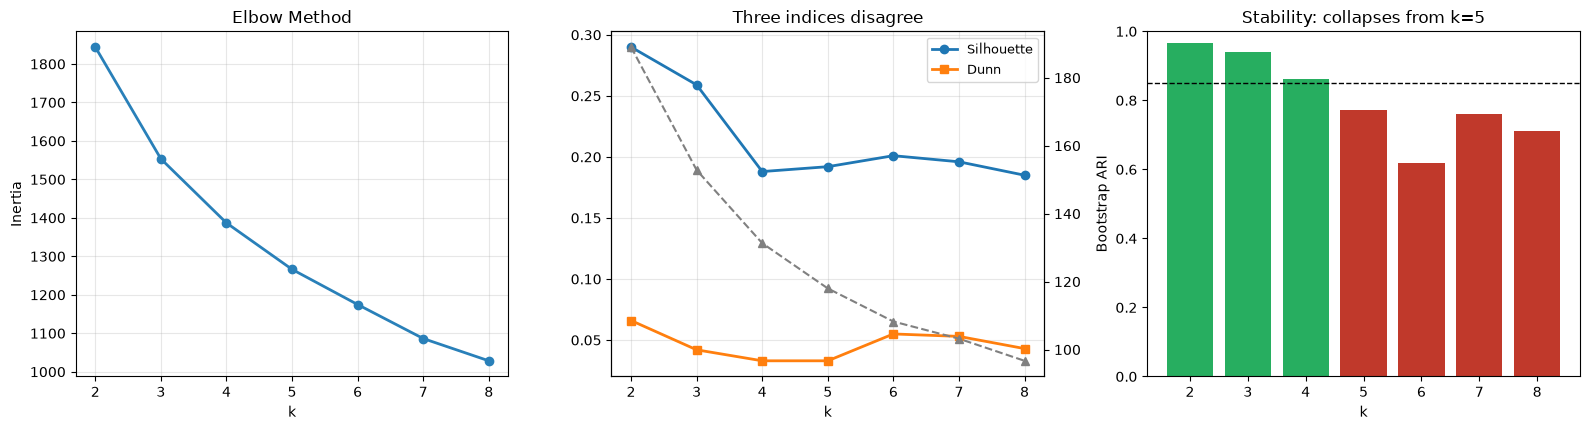

In [8]:
# ============================================================
# [그림 3] Elbow / 지표 / 안정성
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].plot(list(KR), inertia, "o-", lw=2, color="#2980b9")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow Method")
ax[0].grid(alpha=0.3)

ax[1].plot(M4.k, M4.silhouette, "o-", label="Silhouette", lw=2)
ax[1].plot(M4.k, M4.dunn, "s-", label="Dunn", lw=2)
ax2 = ax[1].twinx(); ax2.plot(M4.k, M4.ch, "^--", color="gray", label="CH (right)")
ax[1].set_xlabel("k"); ax[1].set_title("Three indices disagree")
ax[1].legend(loc="upper right", fontsize=9); ax[1].grid(alpha=0.3)

ax[2].bar(M4.k.astype(str), M4["안정성"],
          color=["#27ae60" if v >= 0.85 else "#c0392b" for v in M4["안정성"]])
ax[2].axhline(0.85, ls="--", c="k", lw=1)
ax[2].set_xlabel("k"); ax[2].set_ylabel("Bootstrap ARI"); ax[2].set_ylim(0, 1)
ax[2].set_title("Stability: collapses from k=5")
plt.tight_layout(); plt.savefig("clu_fig3_k.png", dpi=120, bbox_inches="tight"); plt.show()

---

## Step 5. 방법 비교 — K-Means / Hierarchical / DBSCAN

노트북 앞부분(합성데이터)에서 **DBSCAN 이 Moon 데이터에서 압승**했다.
실제 고객 데이터에서도 그럴까?

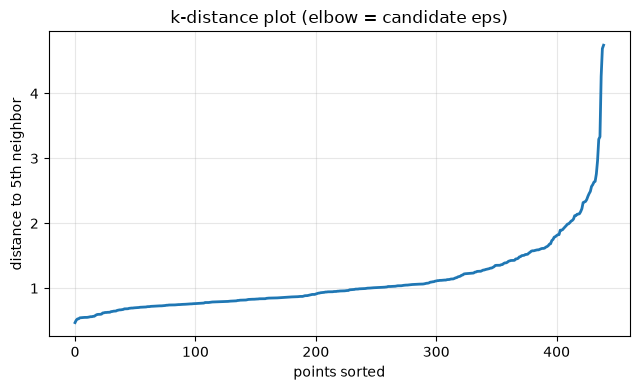

=== DBSCAN: eps 를 바꿔가며 ===
  eps |    클러스터 |          노이즈 | 실루엣
  0.8 |       3 |  230명 ( 52%) | 0.288
  1.0 |       1 |  124명 ( 28%) | 평가불가
  1.2 |       1 |   79명 ( 18%) | 평가불가
  1.5 |       1 |   41명 (  9%) | 평가불가
  2.0 |       1 |   12명 (  3%) | 평가불가
  2.5 |       1 |    4명 (  1%) | 평가불가

[결론] eps 를 어떻게 줘도 '전부 한 덩어리' 아니면 '절반이 노이즈' 다.
       이 데이터는 로그변환 후 밀도 골짜기가 없는 하나의 덩어리라,
       DBSCAN 이 쪼갤 근거가 없다. -> 합성데이터 데모가 실제를 예측해주지 않는다.


In [9]:
# ============================================================
# Step 5-1. DBSCAN 의 eps 를 어떻게 정하나 — k-distance plot
# ============================================================
from sklearn.neighbors import NearestNeighbors
kd = np.sort(NearestNeighbors(n_neighbors=5).fit(X_LOG).kneighbors(X_LOG)[0][:, -1])
plt.figure(figsize=(6.5, 4))
plt.plot(kd, lw=2); plt.xlabel("points sorted"); plt.ylabel("distance to 5th neighbor")
plt.title("k-distance plot (elbow = candidate eps)"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("=== DBSCAN: eps 를 바꿔가며 ===")
print(f"{'eps':>5} | {'클러스터':>7} | {'노이즈':>12} | 실루엣")
for eps in [0.8, 1.0, 1.2, 1.5, 2.0, 2.5]:
    lb = DBSCAN(eps=eps, min_samples=5).fit_predict(X_LOG)
    n = len(set(lb)) - (1 if -1 in lb else 0); nz = int((lb == -1).sum())
    s = score_all(X_LOG, lb)["silhouette"]
    print(f"{eps:>5} | {n:>7} | {nz:>4}명 ({nz/len(lb)*100:3.0f}%) | "
          f"{'평가불가' if np.isnan(s) else f'{s:.3f}'}")
print("\n[결론] eps 를 어떻게 줘도 '전부 한 덩어리' 아니면 '절반이 노이즈' 다.")
print("       이 데이터는 로그변환 후 밀도 골짜기가 없는 하나의 덩어리라,")
print("       DBSCAN 이 쪼갤 근거가 없다. -> 합성데이터 데모가 실제를 예측해주지 않는다.")

In [10]:
# ============================================================
# Step 5-2. K-Means vs Hierarchical (linkage 4종)
# ============================================================
methods = {"K-Means": KMeans(BEST_K, random_state=RS, n_init=10)}
for lk in ["ward", "complete", "average", "single"]:
    methods[f"Hierarchical({lk})"] = AgglomerativeClustering(BEST_K, linkage=lk)

LAB, rows = {}, []
for nm, mdl in methods.items():
    lb = mdl.fit_predict(X_LOG); LAB[nm] = lb
    s = score_all(X_LOG, lb)
    rows.append(dict(방법=nm, **{a: round(b, 3) for a, b in s.items()},
                     크기=str(sorted(sizes(lb), reverse=True))))
R5 = pd.DataFrame(rows)
print(f"=== 방법 비교 (k={BEST_K}, log1p+표준화) ===")
print(R5.to_string(index=False))

print("\n=== 서로 얼마나 같은 결과인가 (ARI) ===")
ns = list(LAB)
A = pd.DataFrame([[round(adjusted_rand_score(LAB[a], LAB[b]), 2) for b in ns] for a in ns],
                 index=ns, columns=ns)
print(A.to_string())
km_w = adjusted_rand_score(LAB["K-Means"], LAB["Hierarchical(ward)"])
print(f"\n[해석] K-Means 와 Hierarchical(ward) 의 실루엣 차이는 작지만 ARI 는 {km_w:.2f} 다.")
print("       점수가 비슷해도 '누가 어느 그룹에 들어가는지' 는 다르다.")
print("       single linkage 는 한 덩어리에 몰리는 chaining 현상을 보인다. (교재 p.59)")

=== 방법 비교 (k=4, log1p+표준화) ===
                    방법  silhouette      ch  dunn                  크기
               K-Means       0.188 131.320 0.033 [132, 129, 118, 61]
    Hierarchical(ward)       0.202 108.607 0.055  [208, 125, 54, 53]
Hierarchical(complete)       0.260  38.944 0.096    [391, 33, 11, 5]
 Hierarchical(average)       0.498   8.383 0.336      [437, 1, 1, 1]
  Hierarchical(single)       0.498   8.383 0.336      [437, 1, 1, 1]

=== 서로 얼마나 같은 결과인가 (ARI) ===
                        K-Means  Hierarchical(ward)  Hierarchical(complete)  Hierarchical(average)  Hierarchical(single)
K-Means                    1.00                0.40                    0.03                   -0.0                  -0.0
Hierarchical(ward)         0.40                1.00                    0.05                    0.0                   0.0
Hierarchical(complete)     0.03                0.05                    1.00                    0.1                   0.1
Hierarchical(average)     -0.00          

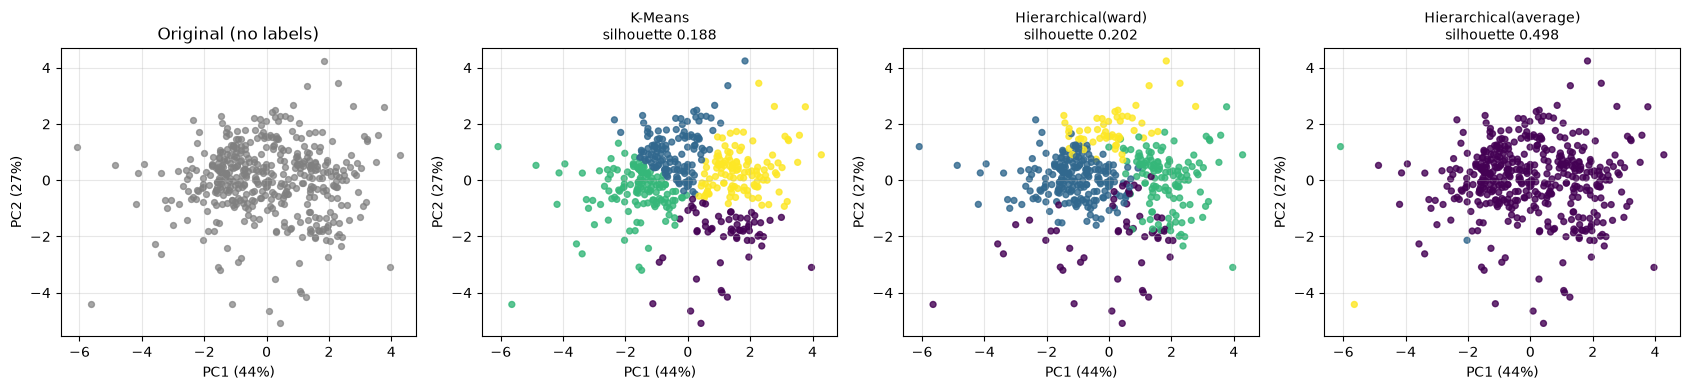

PCA 2개 주성분이 설명하는 분산: 71.3%


In [11]:
# ============================================================
# [그림 4] PCA 2차원에 투영해 방법별 결과 비교 (교재 p.67)
# ============================================================
P2 = PCA(n_components=2, random_state=RS).fit(X_LOG)
Z = P2.transform(X_LOG)
show = ["K-Means", "Hierarchical(ward)", "Hierarchical(average)"]
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].scatter(Z[:, 0], Z[:, 1], c="gray", s=18, alpha=0.7)
ax[0].set_title("Original (no labels)")
for a, nm in zip(ax[1:], show):
    a.scatter(Z[:, 0], Z[:, 1], c=LAB[nm], cmap="viridis", s=18, alpha=0.8)
    a.set_title(f"{nm}\nsilhouette {score_all(X_LOG, LAB[nm])['silhouette']:.3f}", fontsize=10)
for a in ax:
    a.set_xlabel(f"PC1 ({P2.explained_variance_ratio_[0]*100:.0f}%)")
    a.set_ylabel(f"PC2 ({P2.explained_variance_ratio_[1]*100:.0f}%)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("clu_fig4_methods.png", dpi=120, bbox_inches="tight"); plt.show()
print(f"PCA 2개 주성분이 설명하는 분산: {P2.explained_variance_ratio_.sum()*100:.1f}%")

---

## Step 6. Customer Profiling — 진짜 산출물 ★

교재 p.72: *"특성화: 클러스터 내 객체들의 특성 중심으로 파악 / 차별화: 다른 클러스터와의 차이"*

숫자를 그대로 보면 감이 안 오므로 **전체 중앙값 대비 몇 배인지**로 바꿔서 본다.
평균이 아니라 **중앙값**을 쓰는 이유는 이상치 때문이다.

In [12]:
# ============================================================
# Step 6. 클러스터별 프로파일
# ============================================================
FINAL = KMeans(BEST_K, random_state=RS, n_init=10).fit_predict(X_LOG)
df["cluster"] = FINAL

prof = df.groupby("cluster")[SPEND].median()
ratio = prof / df[SPEND].median()
info = pd.DataFrame({"고객수": df.groupby("cluster").size(),
                     "비중": (df.groupby("cluster").size()/len(df)*100).round(0)})
if "Channel" in df:
    info["Retail%"] = (df.groupby("cluster")["Channel"].apply(lambda s: (s == 2).mean()*100)).round(0)

print("=== 클러스터별 지출 중앙값 (실제 금액) ===")
print(pd.concat([prof.round(0), info], axis=1).to_string())
print("\n=== 전체 중앙값 대비 배수 (1.0 = 평균적인 고객) ===")
print(ratio.round(2).to_string())

# 자동 라벨링: '높은 것' 뿐 아니라 '없는 것' 까지 봐야 구별된다
KOR = {"Fresh":"신선", "Milk":"유제품", "Grocery":"식료품", "Frozen":"냉동",
       "Detergents_Paper":"생활용품", "Delicassen":"델리"}

def name_of(r):
    hi = r[r >= 1.8].sort_values(ascending=False)
    lo = r[r <= 0.40].sort_values()
    if len(hi) == 0 and len(lo) > 0:
        return "전 품목 소량 (저활동)"
    if len(hi) == 0:
        return "평균형"
    h = "+".join(KOR[c] for c in hi.index[:2])
    if len(lo) > 0:
        return f"{h} 중심 / {'+'.join(KOR[c] for c in lo.index[:2])} 미취급"
    return f"{h} 중심 (전 품목 대량)"

print("\n=== 프로파일 요약 ===")
for c in sorted(df["cluster"].unique()):
    r = ratio.loc[c]
    top = r.sort_values(ascending=False)
    print(f"\n  [Cluster {c}]  {info.loc[c,'고객수']}명 ({info.loc[c,'비중']:.0f}%)"
          + (f", Retail 비율 {info.loc[c,'Retail%']:.0f}%" if "Retail%" in info else ""))
    print(f"    특징: {name_of(r)}")
    print(f"    높음: " + ", ".join(f"{k}({v:.1f}x)" for k, v in top[top >= 1.5].items()))
    print(f"    낮음: " + ", ".join(f"{k}({v:.1f}x)" for k, v in top[top <= 0.6].items()))

=== 클러스터별 지출 중앙값 (실제 금액) ===
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen  고객수    비중  Retail%
cluster                                                                                    
0         1073.0  6964.0  10518.0   340.0            4508.0       295.0   61  14.0     66.0
1        17023.0  3086.0   3445.0  4324.0             529.0      1404.0  129  29.0      5.0
2         7814.0  1114.0   1820.0  1390.0             224.0       435.0  132  30.0      1.0
3         7832.0  8482.0  12272.0  1347.0            4644.0      1682.0  118  27.0     80.0

=== 전체 중앙값 대비 배수 (1.0 = 평균적인 고객) ===
         Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                            
0         0.13  1.92     2.21    0.22              5.52        0.31
1         2.00  0.85     0.72    2.83              0.65        1.45
2         0.92  0.31     0.38    0.91              0.27        0.45
3         0.92  2.34     2.58    0.88    

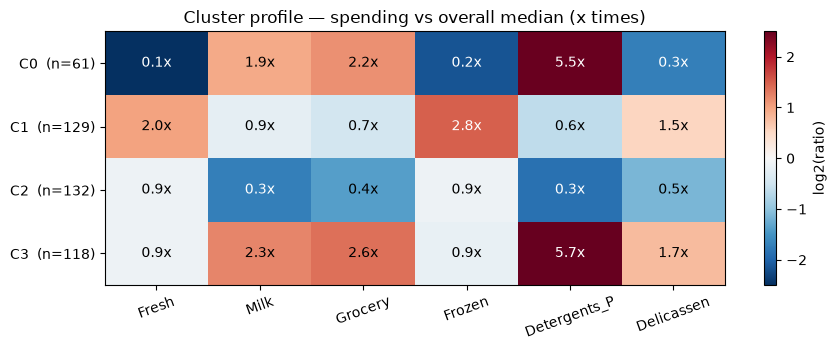

In [13]:
# ============================================================
# [그림 5] 프로파일 히트맵 — 제출물의 핵심 그림
# ============================================================
fig, ax = plt.subplots(figsize=(9, 3.6))
V = np.log2(ratio.values)          # 1.0배=0, 2배=+1, 0.5배=-1
im = ax.imshow(V, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(SPEND))); ax.set_xticklabels([c[:12] for c in SPEND], rotation=20)
ax.set_yticks(range(len(ratio)))
ax.set_yticklabels([f"C{c}  (n={info.loc[c,'고객수']})" for c in ratio.index])
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        ax.text(j, i, f"{ratio.values[i,j]:.1f}x", ha="center", va="center",
                fontsize=10, color="white" if abs(V[i, j]) > 1.4 else "black")
ax.set_title("Cluster profile — spending vs overall median (x times)")
plt.colorbar(im, ax=ax, label="log2(ratio)")
plt.tight_layout(); plt.savefig("clu_fig5_profile.png", dpi=120, bbox_inches="tight"); plt.show()

---

## Step 7. 외부 검증 — `Channel` / `Region` 과 대조

`Channel` 은 **클러스터링 입력에 넣지 않았다.** 그런데도 결과가 `Channel` 구조를
찾아냈다면, 그건 우리 세그먼트가 **실제 사업 구조를 반영한다는 증거**다.
동시에 `Channel` 만으로는 안 보이던 그룹을 더 찾아냈다면 그게 **부가가치**다.

In [14]:
# ============================================================
# Step 7. 입력에 넣지 않은 변수로 검증
# ============================================================
for v in VALID:
    ct = pd.crosstab(df["cluster"], df[v])
    print(f"=== cluster x {v} ===")
    print(ct.to_string())
    print(f"  ARI = {adjusted_rand_score(df[v].values, FINAL):.3f}\n")

if "Channel" in df:
    ari2 = adjusted_rand_score(df["Channel"].values,
                              KMeans(2, random_state=RS, n_init=10).fit_predict(X_LOG))
    ariK = adjusted_rand_score(df["Channel"].values, FINAL)
    print("[해석]")
    print(f"  k=2 의 Channel ARI = {ari2:.3f}  -> 2개로 나누면 사실상 Channel 을 재발견한다")
    print(f"  k={BEST_K} 의 Channel ARI = {ariK:.3f}  -> Channel 구조를 담되 그 안을 더 쪼갠다")
    ct = pd.crosstab(df["cluster"], df["Channel"])
    print("\n  각 Channel 이 몇 개 클러스터로 나뉘는가:")
    for chv in ct.columns:
        n = (ct[chv] >= 20).sum()
        nm = "Horeca(식당·카페)" if chv == 1 else "Retail(소매)"
        print(f"    Channel {chv} {nm}: {n}개 클러스터로 세분화")
    print("\n  -> '이미 아는 2개' 를 넘어 실제로 더 잘게 나눴다는 것이 이 세그먼테이션의 부가가치다.")

=== cluster x Channel ===
Channel    1   2
cluster         
0         21  40
1        122   7
2        131   1
3         24  94
  ARI = 0.280

=== cluster x Region ===
Region    1   2   3
cluster            
0         8   6  47
1        21  17  91
2        27  11  94
3        21  13  84
  ARI = -0.006

[해석]
  k=2 의 Channel ARI = 0.514  -> 2개로 나누면 사실상 Channel 을 재발견한다
  k=4 의 Channel ARI = 0.280  -> Channel 구조를 담되 그 안을 더 쪼갠다

  각 Channel 이 몇 개 클러스터로 나뉘는가:
    Channel 1 Horeca(식당·카페): 4개 클러스터로 세분화
    Channel 2 Retail(소매): 2개 클러스터로 세분화

  -> '이미 아는 2개' 를 넘어 실제로 더 잘게 나눴다는 것이 이 세그먼테이션의 부가가치다.


---

## 결론 정리

In [15]:
# ============================================================
#  최종 요약 리포트 — 이 셀 하나로 결과 전체 출력
# ============================================================
from IPython.display import display, Markdown
BAR = "=" * 74
print(BAR); print("  FINAL CLUSTERING MODEL"); print(BAR)
print(f"""
  전처리   : log1p  ->  StandardScaler
  입력변수 : {SPEND}
  제외변수 : {VALID}  (검증용)
  알고리즘 : KMeans(n_clusters={BEST_K}, n_init=10, random_state={RS})
""")

display(Markdown("**선정 규칙** (지표 최대화가 아니라 규칙으로 골랐다)"))
display(pd.DataFrame([
    ["① 한 군집 60% 미만",  "세분화가 안 된 해를 배제"],
    ["② 최소 군집 20명 이상", "실무에서 액션 불가한 해를 배제"],
    ["③ 안정성 0.85 이상",   f"k=5 부터 {M4[M4.k==5]['안정성'].iloc[0]:.2f} 로 붕괴"],
    ["④ Channel 재발견 배제", f"k=2 는 Channel ARI {M4[M4.k==2]['Channel_ARI'].iloc[0]:.2f} 로 이미 아는 정보"],
], columns=["규칙", "근거"]).style.hide(axis="index"))

display(Markdown("**최종 세그먼트**"))
summ = pd.concat([info, ratio.round(2)], axis=1)
summ.insert(0, "세그먼트", [name_of(ratio.loc[c]) for c in ratio.index])
display(summ)

display(Markdown("**전처리가 결과를 어떻게 바꿨나** — 공지 Q3 의 답"))
display(pd.DataFrame([
    ["A. 원척도 k=2", R3[(R3.전처리.str.startswith("A")) & (R3.k == 2)].실루엣.iloc[0],
     R3[(R3.전처리.str.startswith("A")) & (R3.k == 2)].크기.iloc[0], "이상치 분리 — 세분화 아님"],
    ["A. 원척도 k=3", R3[(R3.전처리.str.startswith("A")) & (R3.k == 3)].실루엣.iloc[0],
     R3[(R3.전처리.str.startswith("A")) & (R3.k == 3)].크기.iloc[0], "2명짜리 클러스터 발생"],
    [f"B. 로그 k={BEST_K}", R3[(R3.전처리.str.startswith("B")) & (R3.k == BEST_K)].실루엣.iloc[0],
     R3[(R3.전처리.str.startswith("B")) & (R3.k == BEST_K)].크기.iloc[0], "네 덩어리로 고르게 — 채택"],
], columns=["설정", "실루엣", "클러스터 크기", "판정"]).style.hide(axis="index"))

print("  실루엣이 가장 높은 설정이 가장 쓸모없는 세그먼테이션이었다.")
print(f"  채택한 설정의 실루엣({R3[(R3.전처리.str.startswith('B'))&(R3.k==BEST_K)].실루엣.iloc[0]}) 은"
      f" 최고값({R3.실루엣.max()}) 의 절반도 안 된다.\n")

display(Markdown("**방법 비교**"))
display(R5.style.hide(axis="index"))
print(BAR)
print("  결론: 이 실습에서 결과를 만든 것은 알고리즘 선택이 아니라 '로그변환' 이었다.")
print("        DBSCAN 은 실패했고, K-Means 와 Hierarchical 은 점수로 구별되지 않았다.")
print(BAR)

  FINAL CLUSTERING MODEL

  전처리   : log1p  ->  StandardScaler
  입력변수 : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
  제외변수 : ['Channel', 'Region']  (검증용)
  알고리즘 : KMeans(n_clusters=4, n_init=10, random_state=42)



**선정 규칙** (지표 최대화가 아니라 규칙으로 골랐다)

규칙,근거
① 한 군집 60% 미만,세분화가 안 된 해를 배제
② 최소 군집 20명 이상,실무에서 액션 불가한 해를 배제
③ 안정성 0.85 이상,k=5 부터 0.77 로 붕괴
④ Channel 재발견 배제,k=2 는 Channel ARI 0.51 로 이미 아는 정보


**최종 세그먼트**

,세그먼트,고객수,비중,Retail%,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,,,,,
0,생활용품+식료품 중심 / 신선+냉동 미취급,61,14.0,66.0,0.13,1.92,2.21,0.22,5.52,0.31
1,냉동+신선 중심 (전 품목 대량),129,29.0,5.0,2.00,0.85,0.72,2.83,0.65,1.45
2,전 품목 소량 (저활동),132,30.0,1.0,0.92,0.31,0.38,0.91,0.27,0.45
3,생활용품+식료품 중심 (전 품목 대량),118,27.0,80.0,0.92,2.34,2.58,0.88,5.69,1.74


...

설정,실루엣,클러스터 크기,판정
A. 원척도 k=2,0.547000,"[389, 51]",이상치 분리 — 세분화 아님
A. 원척도 k=3,0.548000,"[45, 393, 2]",2명짜리 클러스터 발생
B. 로그 k=4,0.188000,"[61, 129, 132, 118]",네 덩어리로 고르게 — 채택


  실루엣이 가장 높은 설정이 가장 쓸모없는 세그먼테이션이었다.
  채택한 설정의 실루엣(0.188) 은 최고값(0.548) 의 절반도 안 된다.



**방법 비교**

방법,silhouette,ch,dunn,크기
K-Means,0.188000,131.320000,0.033000,"[132, 129, 118, 61]"
Hierarchical(ward),0.202000,108.607000,0.055000,"[208, 125, 54, 53]"
Hierarchical(complete),0.260000,38.944000,0.096000,"[391, 33, 11, 5]"
Hierarchical(average),0.498000,8.383000,0.336000,"[437, 1, 1, 1]"
Hierarchical(single),0.498000,8.383000,0.336000,"[437, 1, 1, 1]"


  결론: 이 실습에서 결과를 만든 것은 알고리즘 선택이 아니라 '로그변환' 이었다.
        DBSCAN 은 실패했고, K-Means 와 Hierarchical 은 점수로 구별되지 않았다.
